In [1]:

!pip install imbalanced-learn -q


First 5 Rows:


,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False



Dataset Shape:
(800, 13)

Column Names:
Index(['#', 'Name', 'Type 1', 'Type 2', 'Total', 'HP', 'Attack', 'Defense',
       'Sp. Atk', 'Sp. Def', 'Speed', 'Generation', 'Legendary'],
      dtype='object')

Data Types:
#              int64
Name          object
Type 1        object
Type 2        object
Total          int64
HP             int64
Attack         int64
Defense        int64
Sp. Atk        int64
Sp. Def        int64
Speed          int64
Generation     int64
Legendary       bool
dtype: object

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   #           800 non-null    int64 
 1   Name        800 non-null    object
 2   Type 1      800 non-null    object
 3   Type 2      414 non-null    object
 4   Total       800 non-null    int64 
 5   HP          800 non-null    int64 
 6   Attack      800 non-null    int64 
 7   Defense   

,#,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
count,800.000000,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000
mean,362.813750,435.10250,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,3.32375
std,208.343798,119.96304,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,1.66129
min,1.000000,180.00000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,1.00000
25%,184.750000,330.00000,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,2.00000
50%,364.500000,450.00000,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,3.00000
75%,539.250000,515.00000,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,5.00000
max,721.000000,780.00000,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,6.00000



Unique Pokemon Types:
['Grass' 'Fire' 'Water' 'Bug' 'Normal' 'Poison' 'Electric' 'Ground'
 'Fairy' 'Fighting' 'Psychic' 'Rock' 'Ghost' 'Ice' 'Dragon' 'Dark' 'Steel'
 'Flying']

Number of Unique Primary Types:
18

Duplicate Rows:
0

Top 10 Pokemon by Total Stats:


,Name,Total
426,RayquazaMega Rayquaza,780
163,MewtwoMega Mewtwo X,780
164,MewtwoMega Mewtwo Y,780
422,KyogrePrimal Kyogre,770
424,GroudonPrimal Groudon,770
552,Arceus,720
418,LatiasMega Latias,700
494,GarchompMega Garchomp,700
413,MetagrossMega Metagross,700
796,DiancieMega Diancie,700



Legendary Pokemon Count:
Legendary
False    735
True      65
Name: count, dtype: int64


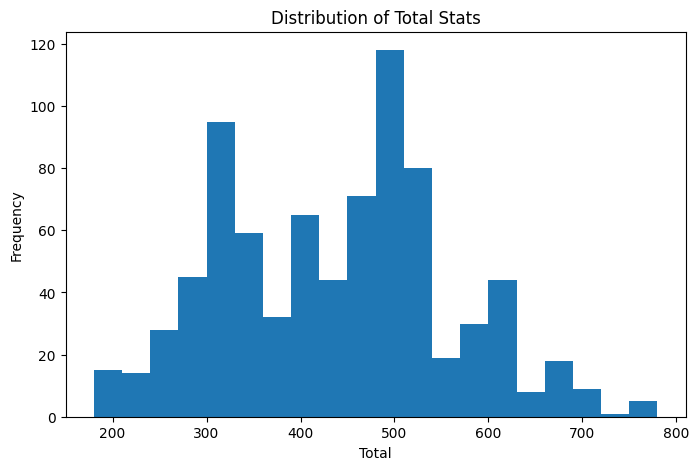

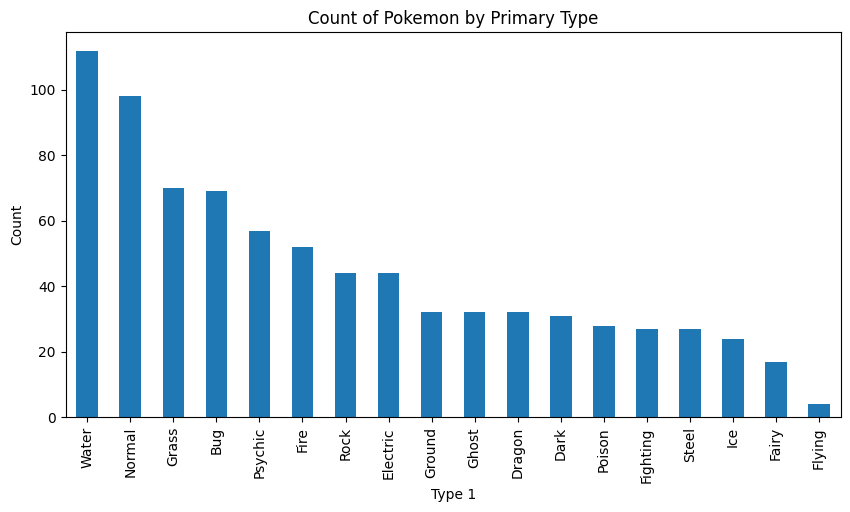

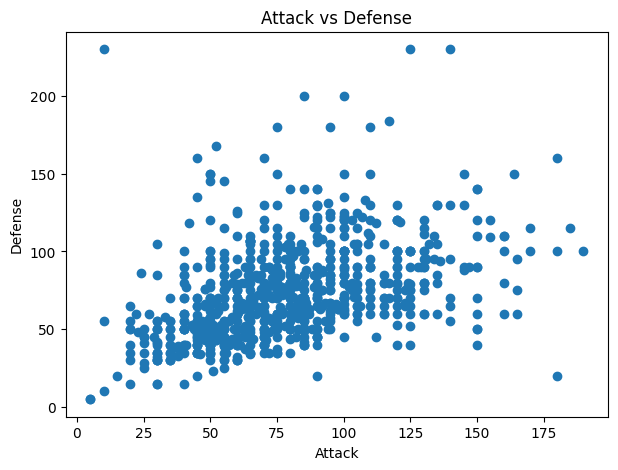


Correlation Matrix:


,#,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
#,1.000000,0.119813,0.097614,0.102298,0.094786,0.088759,0.085817,0.010733,0.982516
Total,0.119813,1.000000,0.618748,0.736211,0.612787,0.747250,0.717609,0.575943,0.048384
HP,0.097614,0.618748,1.000000,0.422386,0.239622,0.362380,0.378718,0.175952,0.058683
Attack,0.102298,0.736211,0.422386,1.000000,0.438687,0.396362,0.263990,0.381240,0.051451
Defense,0.094786,0.612787,0.239622,0.438687,1.000000,0.223549,0.510747,0.015227,0.042419
Sp. Atk,0.088759,0.747250,0.362380,0.396362,0.223549,1.000000,0.506121,0.473018,0.036437
Sp. Def,0.085817,0.717609,0.378718,0.263990,0.510747,0.506121,1.000000,0.259133,0.028486
Speed,0.010733,0.575943,0.175952,0.381240,0.015227,0.473018,0.259133,1.000000,-0.023121
Generation,0.982516,0.048384,0.058683,0.051451,0.042419,0.036437,0.028486,-0.023121,1.000000


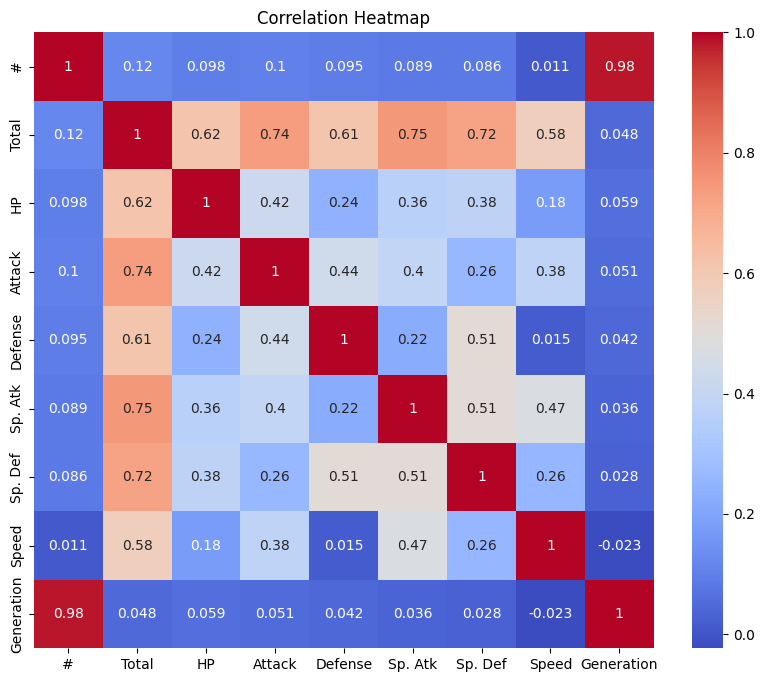

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/pokemon.csv')
print("First 5 Rows:")
display(df.head())
print("\nDataset Shape:")
print(df.shape)
print("\nColumn Names:")
print(df.columns)
print("\nData Types:")
print(df.dtypes)
print("\nDataset Info:")
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nStatistical Summary:")
display(df.describe())
print("\nUnique Pokemon Types:")
print(df['Type 1'].unique())
print("\nNumber of Unique Primary Types:")
print(df['Type 1'].nunique())
print("\nDuplicate Rows:")
print(df.duplicated().sum())

top_total = df[['Name', 'Total']].sort_values(by='Total', ascending=False)
print("\nTop 10 Pokemon by Total Stats:")
display(top_total.head(10))
print("\nLegendary Pokemon Count:")
print(df['Legendary'].value_counts())

plt.figure(figsize=(8, 5))
plt.hist(df['Total'], bins=20)
plt.title("Distribution of Total Stats")
plt.xlabel("Total")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10, 5))
df['Type 1'].value_counts().plot(kind='bar')
plt.title("Count of Pokemon by Primary Type")
plt.xlabel("Type 1")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(df['Attack'], df['Defense'])
plt.title("Attack vs Defense")
plt.xlabel("Attack")
plt.ylabel("Defense")
plt.show()

numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()
print("\nCorrelation Matrix:")
display(corr)

plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


##Noticable things from the EDA
The dataset contains 800 Pokémon with 13 features, including stats like HP, Attack, Defense, and Speed. Most Pokémon are non-legendary, with only 65 legendary Pokémon compared to 735 normal ones. There are no duplicate rows, which means the data is clean, but the `Type 2` column has many missing values because many Pokémon have only one type. The strongest Pokémon based on total stats are Mega Rayquaza and Mega Mewtwo forms with a total score of 780. The average Pokémon total stat is around 435. From the correlation matrix, Total power is strongly connected with Attack, Special Attack, Defense, and Speed, meaning Pokémon with higher combat stats usually have higher overall strength. The dataset also includes 18 unique primary Pokémon types across 6 generations.

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.base import clone

# Drop non-predictive identifier columns
df = df.drop_duplicates()
df = df.drop(columns=['#', 'Name'])

# Outlier removal on Total
Q1 = df['Total'].quantile(0.25)
Q3 = df['Total'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df = df[(df['Total'] >= lower) & (df['Total'] <= upper)]

# Features and target
X = df.drop('Legendary', axis=1)
y = df['Legendary']

# Split BEFORE preprocessing and BEFORE SMOTE to prevent data leakage.
# SMOTE is applied only to the training set after the split.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Class distribution BEFORE SMOTE:")
print(y_train.value_counts())

# Column groups
categorical_cols = ['Type 1', 'Type 2']

# Total excluded: it equals HP+Attack+Defense+Sp.Atk+Sp.Def+Speed (pure multicollinearity)
numerical_cols = ['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed', 'Generation']

# Numerical pipeline
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

# Categorical pipeline
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', num_pipeline, numerical_cols),
    ('cat', cat_pipeline, categorical_cols)
])

# PCA retaining 95% variance
pca = PCA(n_components=0.95, svd_solver='full', random_state=42)

# Master preprocessing + PCA pipeline used as a TEMPLATE — each model clones it
full_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('pca', pca)
])

# Sanity-check shapes
X_train_check = clone(full_pipeline).fit_transform(X_train_raw)
X_test_check  = clone(full_pipeline).fit(X_train_raw).transform(X_test_raw)
print("\nOriginal Training Shape :", X_train_raw.shape)
print("Processed Training Shape:", X_train_check.shape)
print("Original Testing Shape  :", X_test_raw.shape)
print("Processed Testing Shape :", X_test_check.shape)

# Outer CV — stratified to preserve class ratio in every fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Separate inner CV for StackingClassifier blending step (avoids shared state issues)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)


Class distribution BEFORE SMOTE:
Legendary
False    588
True      52
Name: count, dtype: int64

Original Training Shape : (640, 10)
Processed Training Shape: (640, 21)
Original Testing Shape  : (160, 10)
Processed Testing Shape : (160, 21)


Class distribution BEFORE SMOTE (processed train):
Legendary
False    588
True      52
Name: count, dtype: int64
Shape before SMOTE: (640, 21)

Class distribution AFTER SMOTE:
Legendary
False    588
True     588
Name: count, dtype: int64
Shape after SMOTE : (1176, 21)


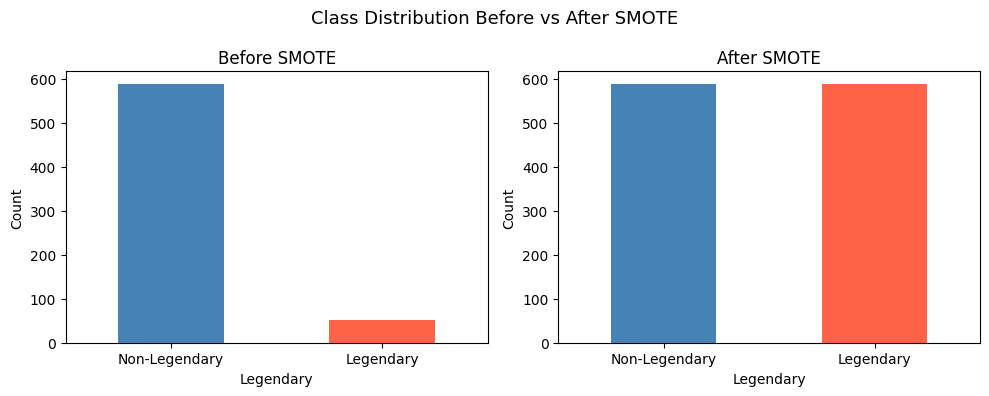

In [4]:
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt

# --- WHY SMOTE GOES HERE ---
# SMOTE (Synthetic Minority Over-sampling TEchnique) synthesises new minority-
# class samples by interpolating between real ones in feature space.
# It MUST be applied AFTER the train/test split and ONLY on training data so
# the test set remains a clean, unseen, real-distribution hold-out.
#
# SMOTE also requires purely numerical input, so we run it on the
# preprocessed+PCA-reduced training array, not the raw DataFrame.
# We therefore fit one dedicated preprocessing+PCA pipeline here to produce
# the arrays that SMOTE operates on, and store that fitted transformer so we
# can apply the same transform to X_test_raw in the evaluation cell.

# Fit preprocessing on the raw training data (no leakage from test)
smote_preprocessor = clone(full_pipeline)
X_train_proc = smote_preprocessor.fit_transform(X_train_raw)
X_test_proc  = smote_preprocessor.transform(X_test_raw)

print("Class distribution BEFORE SMOTE (processed train):")
print(y_train.value_counts())
print(f"Shape before SMOTE: {X_train_proc.shape}")

# Apply SMOTE — k_neighbors=5 is the default; safe with 52 minority samples.
# sampling_strategy='minority' oversamples only the legendary class to match
# the majority count, giving a perfectly balanced training set.
smote = SMOTE(sampling_strategy='minority', k_neighbors=5, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_proc, y_train)

print("\nClass distribution AFTER SMOTE:")
import pandas as pd
print(pd.Series(y_train_smote).value_counts())
print(f"Shape after SMOTE : {X_train_smote.shape}")

# Bar chart: before vs after
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
y_train.value_counts().plot(kind='bar', ax=axes[0], color=['steelblue','tomato'])
axes[0].set_title("Before SMOTE")
axes[0].set_xlabel("Legendary")
axes[0].set_ylabel("Count")
axes[0].set_xticklabels(['Non-Legendary','Legendary'], rotation=0)

pd.Series(y_train_smote).value_counts().plot(kind='bar', ax=axes[1], color=['steelblue','tomato'])
axes[1].set_title("After SMOTE")
axes[1].set_xlabel("Legendary")
axes[1].set_ylabel("Count")
axes[1].set_xticklabels(['Non-Legendary','Legendary'], rotation=0)

plt.suptitle("Class Distribution Before vs After SMOTE", fontsize=13)
plt.tight_layout()
plt.show()


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline

# After SMOTE the training data is already preprocessed (numerical arrays).
# We train directly on X_train_smote / y_train_smote — NO pipeline wrapper
# needed here for preprocessing because that was done before SMOTE.
# We keep a simple classifier (no inner preprocessing pipeline) for SMOTE models.

rf_smote = RandomForestClassifier(
    class_weight='balanced',   # extra safety net on top of SMOTE
    oob_score=True,
    random_state=42
)

rf_smote_params = {
    'n_estimators'     : [400, 500, 600],
    'max_depth'        : [20, 25, 30, None],
    'min_samples_split': [2, 5],
    'max_features'     : ['sqrt', 'log2'],
    'min_samples_leaf' : [1, 2]
}

# SMOTE models use StratifiedKFold on the balanced SMOTE data
rf_smote_search = RandomizedSearchCV(
    estimator           = rf_smote,
    param_distributions = rf_smote_params,
    n_iter              = 10,
    scoring             = 'f1',
    cv                  = StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state        = 42,
    n_jobs              = -1
)

rf_smote_search.fit(X_train_smote, y_train_smote)
rf_smote_model = rf_smote_search.best_estimator_

print("Best Params (RF + SMOTE) :", rf_smote_search.best_params_)
print("Best CV F1-Score         :", round(rf_smote_search.best_score_, 4))


Best Params (RF + SMOTE) : {'n_estimators': 600, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}
Best CV F1-Score         : 0.985


In [6]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV

# CNB sub-pipeline: MinMaxScaler shifts PCA output (which can be negative)
# to [0, 1] so ComplementNB receives valid non-negative counts.
cnb_subpipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('cnb',    ComplementNB())
])

base_models_voting = [
    ('rf',  RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)),
    ('cnb', cnb_subpipeline),
    ('svc', SVC(probability=True, kernel='rbf', class_weight='balanced', random_state=42)),
    ('lr',  LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
]

voting_smote = VotingClassifier(estimators=base_models_voting, voting='soft')

voting_smote_params = {
    'rf__n_estimators'  : [200, 300, 400],
    'rf__max_depth'     : [10, 15, 20],
    'cnb__cnb__alpha'   : [0.1, 0.5, 1.0],
    'svc__C'            : [0.1, 1.0, 10.0],
    'svc__gamma'        : ['scale', 'auto'],
    'lr__C'             : [0.1, 1.0, 10.0],
    'lr__solver'        : ['lbfgs', 'liblinear'],
    'weights'           : [[2, 1, 1, 2], [3, 1, 1, 2], [2, 1, 1, 3]]
}

voting_smote_search = RandomizedSearchCV(
    estimator           = voting_smote,
    param_distributions = voting_smote_params,
    n_iter              = 10,
    scoring             = 'f1',
    cv                  = StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state        = 42,
    n_jobs              = -1
)

voting_smote_search.fit(X_train_smote, y_train_smote)
voting_smote_model = voting_smote_search.best_estimator_

print("Best Params (Voting + SMOTE) :", voting_smote_search.best_params_)
print("Best CV F1-Score             :", round(voting_smote_search.best_score_, 4))


Best Params (Voting + SMOTE) : {'weights': [2, 1, 1, 3], 'svc__gamma': 'scale', 'svc__C': 10.0, 'rf__n_estimators': 400, 'rf__max_depth': 10, 'lr__solver': 'liblinear', 'lr__C': 10.0, 'cnb__cnb__alpha': 0.1}
Best CV F1-Score             : 0.985


In [7]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV

ada_smote = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(class_weight='balanced'),
    random_state=42
)

ada_smote_params = {
    'n_estimators'         : [200, 250, 300, 350],
    'learning_rate'        : [0.01, 0.05, 0.1, 0.5],
    'estimator__max_depth' : [1, 2, 3, 5]
}

ada_smote_search = RandomizedSearchCV(
    estimator           = ada_smote,
    param_distributions = ada_smote_params,
    n_iter              = 10,
    scoring             = 'f1',
    cv                  = StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state        = 42,
    n_jobs              = -1
)

ada_smote_search.fit(X_train_smote, y_train_smote)
adaboost_smote_model = ada_smote_search.best_estimator_

print("Best Params (AdaBoost + SMOTE) :", ada_smote_search.best_params_)
print("Best CV Score                  :", round(ada_smote_search.best_score_, 4))


Best Params (AdaBoost + SMOTE) : {'n_estimators': 250, 'learning_rate': 0.5, 'estimator__max_depth': 5}
Best CV Score                  : 0.985


In [8]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV

cnb_subpipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('cnb',    ComplementNB())
])

base_models_stacking = [
    ('rf',  RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)),
    ('cnb', cnb_subpipeline),
    ('svc', SVC(probability=True, kernel='rbf', class_weight='balanced', random_state=42)),
    ('lr',  LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
]

stacking_smote = StackingClassifier(
    estimators=base_models_stacking,
    final_estimator=LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    # StratifiedKFold for blending: guarantees legendary samples in every fold
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
)

stacking_smote_params = {
    'rf__n_estimators'           : [50, 100, 150],
    'rf__max_depth'              : [5, 10, None],
    'cnb__cnb__alpha'            : [0.1, 0.5, 1.0],
    'svc__C'                     : [0.1, 1.0, 10.0],
    'svc__gamma'                 : ['scale', 'auto'],
    'lr__C'                      : [0.1, 1.0, 10.0],
    'lr__solver'                 : ['lbfgs', 'liblinear'],
    'final_estimator__C'         : [0.1, 1.0, 10.0],
    'final_estimator__solver'    : ['lbfgs', 'liblinear']
}

stacking_smote_search = RandomizedSearchCV(
    estimator           = stacking_smote,
    param_distributions = stacking_smote_params,
    n_iter              = 10,
    scoring             = 'f1',
    cv                  = StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state        = 42,
    n_jobs              = -1
)

stacking_smote_search.fit(X_train_smote, y_train_smote)
stacking_smote_model = stacking_smote_search.best_estimator_

print("Best Params (Stacking + SMOTE) :", stacking_smote_search.best_params_)
print("Best CV F1-Score               :", round(stacking_smote_search.best_score_, 4))


Best Params (Stacking + SMOTE) : {'svc__gamma': 'scale', 'svc__C': 10.0, 'rf__n_estimators': 100, 'rf__max_depth': None, 'lr__solver': 'liblinear', 'lr__C': 1.0, 'final_estimator__solver': 'liblinear', 'final_estimator__C': 10.0, 'cnb__cnb__alpha': 0.5}
Best CV F1-Score               : 0.9966


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# FIX: clone(full_pipeline) gives this model its own independent preprocessing
# copy. Previously all models shared one full_pipeline object, so each .fit()
# call silently overwrote the scaler/PCA learned by every earlier model.
rf_pipeline = Pipeline([
    ('prep_and_pca', clone(full_pipeline)),
    ('model', RandomForestClassifier(
        class_weight='balanced',
        oob_score=True,
        random_state=42
    ))
])

rf_params = {
    'model__n_estimators'     : [400, 500, 600],
    'model__max_depth'        : [20, 25, 30, None],
    'model__min_samples_split': [2, 5],
    'model__max_features'     : ['sqrt', 'log2', 1.0],
    # FIX: Added min_samples_leaf to the search space.
    # Lower values allow trees to specialise on rare legendary samples,
    # which directly helps recall on the minority class.
    'model__min_samples_leaf' : [1, 2]
}

rf_search = RandomizedSearchCV(
    estimator           = rf_pipeline,
    param_distributions = rf_params,
    n_iter              = 10,
    scoring             = 'f1',
    cv                  = cv,
    random_state        = 42,
    n_jobs              = -1
)

rf_search.fit(X_train_raw, y_train)

# FIX: Renamed variable from random_forest_model to rf_model for clarity,
# and fixed the evaluation cell label from 'Bagging' to 'Random Forest'.
# The previous notebook had NO BaggingClassifier — the RF pipeline was
# simply mislabelled 'Bagging' throughout.
rf_model = rf_search.best_estimator_

print("Best Params Chosen :", rf_search.best_params_)
print("Best CV F1-Score   :", round(rf_search.best_score_, 4))


Best Params Chosen : {'model__n_estimators': 400, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 1.0, 'model__max_depth': 25}
Best CV F1-Score   : 0.743


In [11]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# FIX: Replaced KNeighborsClassifier with SVC(probability=True, class_weight='balanced').
# KNN has no class_weight parameter so it always biases toward the majority class.
# SVC with class_weight='balanced' penalises misclassifying the rare legendary
# class more heavily, directly improving recall.
#
# FIX: Moved MinMaxScaler INSIDE a sub-pipeline for ComplementNB only.
# Previously a global MinMaxScaler was applied after PCA, meaning RF, KNN and
# LR were all double-scaled (StandardScaler then MinMaxScaler). KNN is distance-
# based so this distorted its behaviour. Now only CNB gets the non-negative
# scaling it requires; the other estimators receive the PCA output directly.
cnb_subpipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('cnb',    ComplementNB())
])

base_models = [
    ('rf',  RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)),
    ('cnb', cnb_subpipeline),
    ('svc', SVC(probability=True, kernel='rbf', class_weight='balanced', random_state=42)),
    ('lr',  LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
]

voting_pipeline = Pipeline([
    ('prep_and_pca', clone(full_pipeline)),   # FIX: independent clone
    ('model', VotingClassifier(estimators=base_models, voting='soft'))
])

voting_params = {
    'model__rf__n_estimators'    : [200, 300, 400],
    'model__rf__max_depth'       : [10, 15, 20],
    'model__cnb__cnb__alpha'     : [0.1, 0.5, 1.0],
    'model__svc__C'              : [0.1, 1.0, 10.0],
    'model__svc__gamma'          : ['scale', 'auto'],
    'model__lr__C'               : [0.1, 1.0, 10.0],
    'model__lr__solver'          : ['lbfgs', 'liblinear'],
    # FIX: Increased LR and RF weights relative to others.
    # Both support class_weight='balanced' which makes them more recall-aware.
    # Giving them higher votes pulls the ensemble decision boundary toward
    # catching more legendaries (higher recall).
    'model__weights'             : [[2, 1, 1, 2], [3, 1, 1, 2], [2, 1, 1, 3]]
}

voting_search = RandomizedSearchCV(
    estimator           = voting_pipeline,
    param_distributions = voting_params,
    n_iter              = 10,
    scoring             = 'f1',
    cv                  = cv,
    random_state        = 42,
    n_jobs              = -1
)

voting_search.fit(X_train_raw, y_train)

voting_model = voting_search.best_estimator_

print("Best Params Chosen :", voting_search.best_params_)
print("Best CV F1-Score   :", round(voting_search.best_score_, 4))


Best Params Chosen : {'model__weights': [3, 1, 1, 2], 'model__svc__gamma': 'auto', 'model__svc__C': 10.0, 'model__rf__n_estimators': 400, 'model__rf__max_depth': 20, 'model__lr__solver': 'liblinear', 'model__lr__C': 0.1, 'model__cnb__cnb__alpha': 0.5}
Best CV F1-Score   : 0.8009


In [12]:


from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone

ada_pipeline = Pipeline([
    ('prep_and_pca', clone(full_pipeline)),   # FIX: independent clone
    ('model', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(class_weight='balanced'),
        random_state=42
    ))
])

ada_param_dist = {
    'model__n_estimators'         : [200, 250, 300, 350],
    'model__learning_rate'        : [0.01, 0.05, 0.1, 0.5],
    'model__estimator__max_depth' : [1, 2, 3, 5]
}

ada_search = RandomizedSearchCV(
    estimator           = ada_pipeline,
    param_distributions = ada_param_dist,
    n_iter              = 10,
    scoring             = 'f1',
    cv                  = cv,
    random_state        = 42,
    n_jobs              = -1
)

ada_search.fit(X_train_raw, y_train)
adaboost_model = ada_search.best_estimator_

print("Best Params (AdaBoost) :", ada_search.best_params_)
print("Best CV Score          :", round(ada_search.best_score_, 4))


Best Params (AdaBoost) : {'model__n_estimators': 200, 'model__learning_rate': 0.05, 'model__estimator__max_depth': 3}
Best CV Score          : 0.7714


In [13]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# FIX: Same CNB sub-pipeline fix as Voting — MinMaxScaler only wraps CNB,
# not the entire pipeline, so RF, SVC and LR are not double-scaled.
cnb_subpipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('cnb',    ComplementNB())
])

# FIX: Replaced KNeighborsClassifier with SVC(class_weight='balanced')
# for the same reason as in the Voting cell — KNN cannot be balanced.
base_models = [
    ('rf',  RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)),
    ('cnb', cnb_subpipeline),
    ('svc', SVC(probability=True, kernel='rbf', class_weight='balanced', random_state=42)),
    ('lr',  LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
]

stacking_pipeline = Pipeline([
    ('prep_and_pca', clone(full_pipeline)),   # FIX: independent clone
    ('model', StackingClassifier(
        estimators=base_models,
        final_estimator=LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
        # FIX: Replaced cv=5 (unstratified integer) with inner_cv (StratifiedKFold).
        # With ~52 legendaries in training, plain KFold can produce folds with
        # zero legendary samples, breaking or severely biasing blending predictions.
        cv=inner_cv
    ))
])

stacking_params = {
    'model__rf__n_estimators'           : [50, 100, 150],
    'model__rf__max_depth'              : [5, 10, None],
    'model__cnb__cnb__alpha'            : [0.1, 0.5, 1.0],
    'model__svc__C'                     : [0.1, 1.0, 10.0],
    'model__svc__gamma'                 : ['scale', 'auto'],
    'model__lr__C'                      : [0.1, 1.0, 10.0],
    'model__lr__solver'                 : ['lbfgs', 'liblinear'],
    'model__final_estimator__C'         : [0.1, 1.0, 10.0],
    'model__final_estimator__solver'    : ['lbfgs', 'liblinear']
}

# FIX: Increased n_iter from 5 to 10. The previous value of 5 was too low
# to meaningfully explore the 9-dimensional hyperparameter space above.
stacking_search = RandomizedSearchCV(
    estimator           = stacking_pipeline,
    param_distributions = stacking_params,
    n_iter              = 10,
    scoring             = 'f1',
    cv                  = cv,
    random_state        = 42,
    n_jobs              = -1
)

stacking_search.fit(X_train_raw, y_train)

stacking_model = stacking_search.best_estimator_

print("Best Params Chosen :", stacking_search.best_params_)
print("Best CV F1-Score   :", round(stacking_search.best_score_, 4))


Best Params Chosen : {'model__svc__gamma': 'scale', 'model__svc__C': 10.0, 'model__rf__n_estimators': 100, 'model__rf__max_depth': 5, 'model__lr__solver': 'lbfgs', 'model__lr__C': 10.0, 'model__final_estimator__solver': 'liblinear', 'model__final_estimator__C': 10.0, 'model__cnb__cnb__alpha': 1.0}
Best CV F1-Score   : 0.77


  MODEL : RF (baseline)  (threshold=0.3)
  Accuracy  : 0.9125   |  Error Rate: 0.0875
  Precision : 0.4737  |  Recall    : 0.6923  |  F1: 0.5625
  ROC-AUC   : 0.9608

  Confusion Matrix:
[[137  10]
 [  4   9]]

  Classification Report:
              precision    recall  f1-score   support

       False       0.97      0.93      0.95       147
        True       0.47      0.69      0.56        13

    accuracy                           0.91       160
   macro avg       0.72      0.81      0.76       160
weighted avg       0.93      0.91      0.92       160

  MODEL : Voting (baseline)  (threshold=0.3)
  Accuracy  : 0.9062   |  Error Rate: 0.0938
  Precision : 0.4615  |  Recall    : 0.9231  |  F1: 0.6154
  ROC-AUC   : 0.9644

  Confusion Matrix:
[[133  14]
 [  1  12]]

  Classification Report:
              precision    recall  f1-score   support

       False       0.99      0.90      0.95       147
        True       0.46      0.92      0.62        13

    accuracy                     

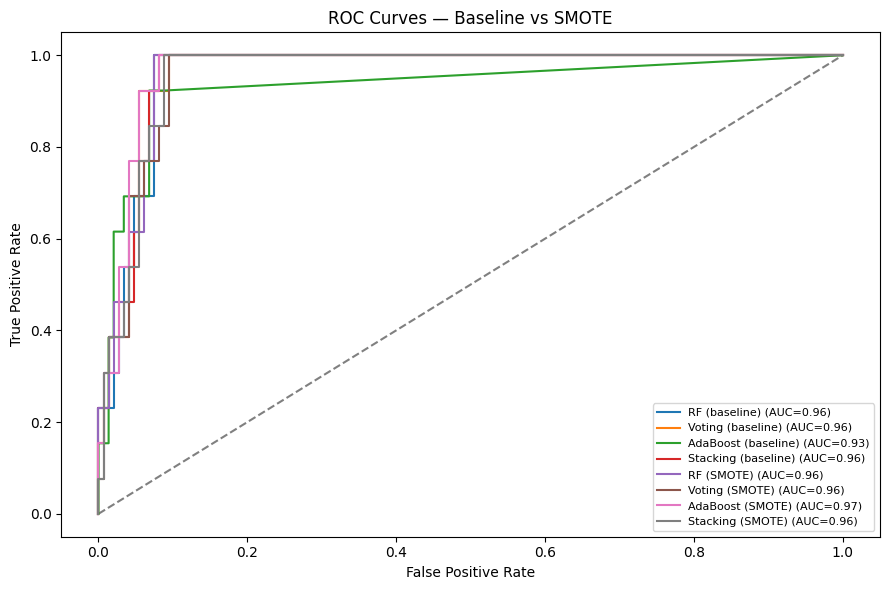


  FULL COMPARISON TABLE (sorted by F1-Score)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,AdaBoost (baseline),0.9313,0.5455,0.9231,0.6857,0.9320
1,Stacking (baseline),0.9187,0.5000,0.9231,0.6486,0.9623
2,AdaBoost (SMOTE),0.9375,0.6000,0.6923,0.6429,0.9686
3,Voting (SMOTE),0.9375,0.6000,0.6923,0.6429,0.9592
4,Voting (baseline),0.9062,0.4615,0.9231,0.6154,0.9644
5,RF (baseline),0.9125,0.4737,0.6923,0.5625,0.9608
6,RF (SMOTE),0.9187,0.5000,0.6154,0.5517,0.9628
7,Stacking (SMOTE),0.9375,0.7143,0.3846,0.5000,0.9602


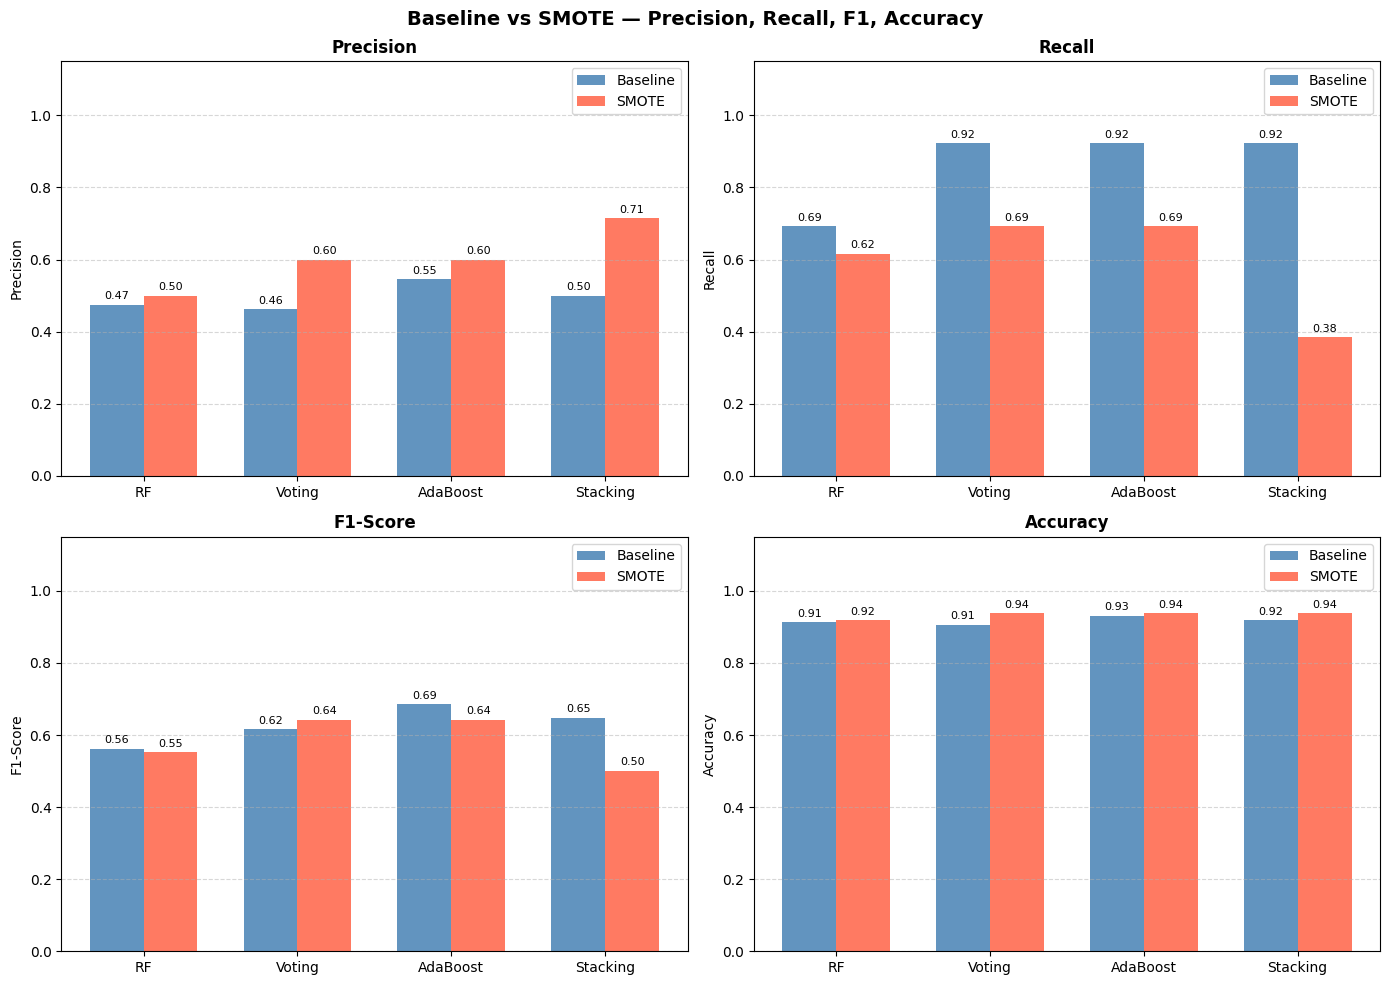

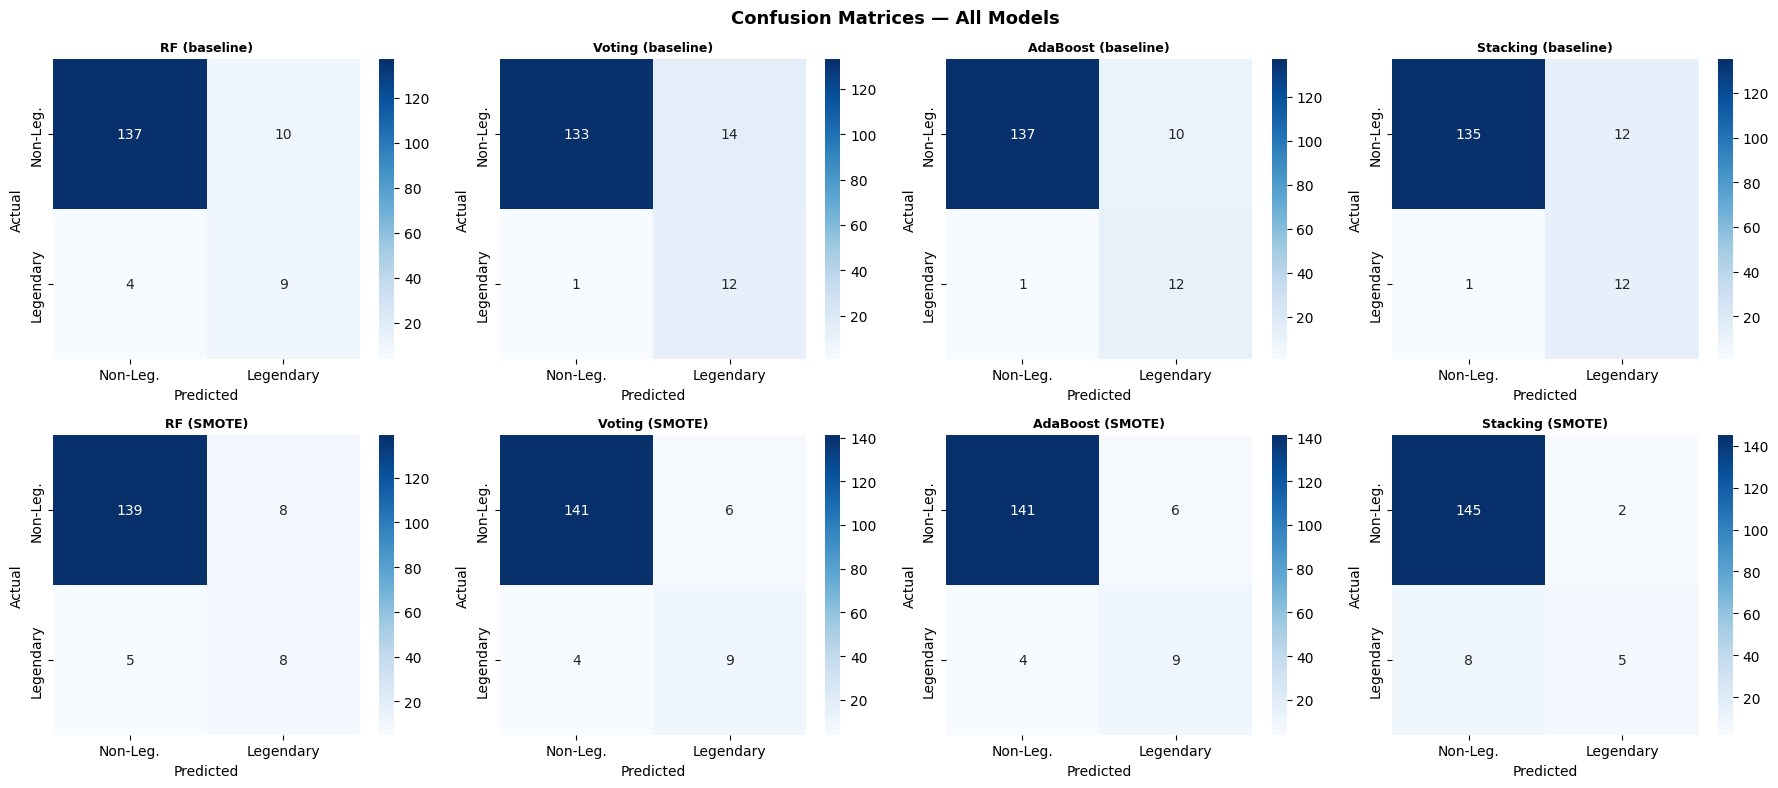

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_curve, auc, precision_score, recall_score, f1_score
)

# ---------------------------------------------------------------------------
# Two groups of models:
#   - Baseline (class_weight only, threshold=0.30 for non-AdaBoost)
#   - SMOTE    (trained on synthetically balanced data, default threshold)
#
# SMOTE models evaluate on X_test_proc (the preprocessed RAW test set via
# smote_preprocessor) because they were trained on processed arrays, not raw.
# Baseline models evaluate on X_test_raw because they carry their own
# preprocessing pipeline inside.
# ---------------------------------------------------------------------------

THRESHOLD = 0.30   # for baseline non-AdaBoost models only

baseline_models = {
    'RF (baseline)'       : (rf_model,        X_test_raw,  THRESHOLD),
    'Voting (baseline)'   : (voting_model,     X_test_raw,  THRESHOLD),
    'AdaBoost (baseline)' : (adaboost_model,   X_test_raw,  0.50),
    'Stacking (baseline)' : (stacking_model,   X_test_raw,  THRESHOLD),
}

smote_models = {
    'RF (SMOTE)'          : (rf_smote_model,      X_test_proc, 0.50),
    'Voting (SMOTE)'      : (voting_smote_model,   X_test_proc, 0.50),
    'AdaBoost (SMOTE)'    : (adaboost_smote_model, X_test_proc, 0.50),
    'Stacking (SMOTE)'    : (stacking_smote_model, X_test_proc, 0.50),
}

all_models = {**baseline_models, **smote_models}

summary_rows = []
roc_fig, roc_ax = plt.subplots(figsize=(9, 6))
roc_ax.plot([0,1],[0,1],'--',color='gray')

for name, (model, X_eval, thresh) in all_models.items():
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_eval)[:, 1]
        y_pred = (y_prob >= thresh).astype(bool)
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_auc = auc(fpr, tpr)
        roc_ax.plot(fpr, tpr, label=f'{name} (AUC={roc_auc:.2f})')
    else:
        y_pred = model.predict(X_eval)
        roc_auc = float('nan')

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)
    cm   = confusion_matrix(y_test, y_pred)

    print("=" * 55)
    print(f"  MODEL : {name}  (threshold={thresh})")
    print("=" * 55)
    print(f"  Accuracy  : {acc:.4f}   |  Error Rate: {1-acc:.4f}")
    print(f"  Precision : {prec:.4f}  |  Recall    : {rec:.4f}  |  F1: {f1:.4f}")
    print(f"  ROC-AUC   : {roc_auc:.4f}" if not np.isnan(roc_auc) else "  ROC-AUC   : N/A")
    print("\n  Confusion Matrix:")
    print(cm)
    print("\n  Classification Report:")
    print(classification_report(y_test, y_pred))

    summary_rows.append({
        'Model'     : name,
        'Accuracy'  : round(acc,  4),
        'Precision' : round(prec, 4),
        'Recall'    : round(rec,  4),
        'F1-Score'  : round(f1,   4),
        'ROC-AUC'   : round(roc_auc, 4) if not np.isnan(roc_auc) else 'N/A'
    })

roc_ax.set_xlabel("False Positive Rate")
roc_ax.set_ylabel("True Positive Rate")
roc_ax.set_title("ROC Curves — Baseline vs SMOTE")
roc_ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# ── Summary comparison table ──────────────────────────────────────────────────
summary_df = pd.DataFrame(summary_rows)
print("\n" + "="*55)
print("  FULL COMPARISON TABLE (sorted by F1-Score)")
print("="*55)
display(summary_df.sort_values('F1-Score', ascending=False).reset_index(drop=True))

# ── Side-by-side bar charts: Baseline vs SMOTE ───────────────────────────────
metrics   = ['Precision', 'Recall', 'F1-Score', 'Accuracy']
model_pairs = [
    ('RF (baseline)',       'RF (SMOTE)'),
    ('Voting (baseline)',   'Voting (SMOTE)'),
    ('AdaBoost (baseline)', 'AdaBoost (SMOTE)'),
    ('Stacking (baseline)', 'Stacking (SMOTE)'),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, metric in zip(axes, metrics):
    baseline_vals = [summary_df.loc[summary_df['Model']==b, metric].values[0] for b,_ in model_pairs]
    smote_vals    = [summary_df.loc[summary_df['Model']==s, metric].values[0] for _,s in model_pairs]
    labels        = ['RF', 'Voting', 'AdaBoost', 'Stacking']
    x = np.arange(len(labels))
    w = 0.35

    bars_b = ax.bar(x - w/2, baseline_vals, w, label='Baseline', color='steelblue', alpha=0.85)
    bars_s = ax.bar(x + w/2, smote_vals,    w, label='SMOTE',    color='tomato',    alpha=0.85)

    for bar in list(bars_b) + list(bars_s):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)

    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0, 1.15)
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("Baseline vs SMOTE — Precision, Recall, F1, Accuracy", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ── Confusion matrix grid ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
all_names = list(all_models.keys())

for ax, (name, (model, X_eval, thresh)) in zip(axes.flatten(), all_models.items()):
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_eval)[:, 1]
        y_pred = (y_prob >= thresh).astype(bool)
    else:
        y_pred = model.predict(X_eval)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Non-Leg.','Legendary'],
                yticklabels=['Non-Leg.','Legendary'])
    ax.set_title(name, fontsize=9, fontweight='bold')
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Confusion Matrices — All Models", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 📊 Results & Model Evaluation

### Dataset & Setup
- **800 Pokémon** | 735 Non-Legendary vs 65 Legendary (~8% minority)
- **Test Set:** 160 samples — 147 Non-Legendary | 13 Legendary
- **Baseline:** `class_weight='balanced'` + threshold=0.30 (AdaBoost kept 0.50)
- **SMOTE:** Applied only on training set after split to prevent data leakage

---

## Baseline Models

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---|---|---|---|---|
| Random Forest | 0.9125 | 0.4737 | 0.6923 | 0.5625 | 0.9608 |
| Voting | 0.9062 | 0.4615 | 0.9231 | 0.6154 | 0.9644 |
| **AdaBoost** | **0.9313** | **0.5455** | **0.9231** | **0.6857** | 0.9320 |
| Stacking | 0.9187 | 0.5000 | 0.9231 | 0.6486 | 0.9623 |

## SMOTE Models

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---|---|---|---|---|
| Random Forest | 0.9187 | 0.5000 | 0.6154 | 0.5517 | 0.9628 |
| Voting | 0.9375 | 0.6000 | 0.6923 | 0.6429 | 0.9592 |
| AdaBoost | 0.9375 | 0.6000 | 0.6923 | 0.6429 | **0.9686** |
| **Stacking** | **0.9375** | **0.7143** | 0.3846 | 0.5000 | 0.9602 |

---

## Key Observations

**1. Baseline prioritises Recall, SMOTE prioritises Precision.**
Lowering the threshold to 0.30 aggressively catches legendaries (high recall). SMOTE trains on a balanced dataset so the model becomes more conservative and precise, but misses more legendaries.

**2. Best F1 → AdaBoost (Baseline) at 0.6857.**
Caught 12 out of 13 legendaries with recall=0.92. Best practical model for this task since missing a legendary is worse than a false alarm.

**3. Best Precision → Stacking (SMOTE) at 0.7143.**
Most confident when predicting legendary, but only caught 5 out of 13 — too many misses.

**4. Best ROC-AUC → AdaBoost (SMOTE) at 0.9686.**
Strongest class separation across all thresholds. All models scored above 0.93, confirming strong discriminative ability regardless of strategy.

**5. SMOTE consistently raised Precision across all models.**

| Model | Baseline Precision | SMOTE Precision | Δ |
|---|---|---|---|
| Random Forest | 0.4737 | 0.5000 | +0.03 |
| Voting | 0.4615 | 0.6000 | +0.14 |
| AdaBoost | 0.5455 | 0.6000 | +0.05 |
| Stacking | 0.5000 | 0.7143 | +0.21 |

**6. SMOTE accuracy is not dramatically higher** because the test set always reflects the real 11:1 imbalance. Accuracy is dominated by the 147 non-legendary samples regardless of strategy.